# 07 · Análisis III: arquitectura de sistemas

**Sección de la tesis:** 6.4 (6.4.1 espaciamiento orbital; 6.4.2 sistemas *gapped*).

**Pregunta.** ¿La masa y la metalicidad de la estrella se relacionan con la arquitectura observada del sistema, una vez considerados el tamaño típico de los planetas y cuántos se detectaron?

**Muestra.** Sistemas con al menos dos planetas de $1$–$4\,R_\oplus$ y $P<100$ días, con masa estelar y metalicidad. La unidad de análisis es el sistema.

**Respuestas.**
- Espaciamiento: `log_median_period_ratio` = $\log_{10}$ de la mediana de las razones de período de planetas adyacentes, $P_{i+1}/P_i$.
- `gapped` = 1 si algún par adyacente tiene $P_{i+1}/P_i > 5$.

**Modelos** (predictores estandarizados):

| Modelo | Respuesta | Tipo | Predictores |
|---|---|---|---|
| S0 (base) | espaciamiento | lineal | `median_radius_z + N_planetas_z` |
| S1 (estelar) | espaciamiento | lineal | `median_radius_z + N_planetas_z + st_mass_z + st_met_z` |
| G0 (base) | `gapped` | logístico | `median_radius_z + N_planetas_z` |
| G1 (estelar) | `gapped` | logístico | `median_radius_z + N_planetas_z + st_mass_z + st_met_z` |

**Salidas:** tablas A3-T1 a A3-T9; figuras A3-F1 y A3-F2; `data_processed/04_planetas_en_sistemas.csv` y `05_sistemas_planetarios_enriquecido.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

## 1. Construcción de la muestra de sistemas

In [2]:
df = cargar_catalogo()
candidatos, criterios = planetas_candidatos_arquitectura(df)
sistemas = construir_sistemas(candidatos)
CONTROLES = ["median_radius_z", "N_planetas_z"]
ESTELARES = ["st_mass_z", "st_met_z"]
sistemas = estandarizar(sistemas, ["median_radius", "N_planetas", "st_mass", "st_met"])

candidatos.to_csv(DATOS_PROCESADOS / "04_planetas_en_sistemas.csv", index=False)
sistemas.to_csv(DATOS_PROCESADOS / "05_sistemas_planetarios_enriquecido.csv", index=False)
print(f"Sistemas: {len(sistemas)} | planetas: {sistemas['N_planetas'].sum()} | gapped: {sistemas['gapped'].sum()}")

tabla_criterios = guardar_tabla(
    criterios, "A3-T1", "construccion_muestra_de_sistemas",
    titulo="Análisis III: construcción de la muestra de sistemas multiplanetarios.",
    seccion="6.4",
    nota="Las razones de período se calculan solo entre los planetas que cumplen los criterios, ordenados por período.")
tabla_criterios

Sistemas: 615 | planetas: 1513 | gapped: 85
Tabla A3-T1 guardada: tablas/A3-T1_construccion_muestra_de_sistemas.csv


,paso,N_planetas,N_estrellas
0,Catálogo limpio,6267,4711
1,"Con radio, período, [Fe/H] y masa estelar",5578,4105
2,Radio planetario entre 1 y 4 R_Tierra,3371,2419
3,Período orbital menor que 100 días,3238,2340
4,En sistemas con al menos 2 planetas que cumple...,1513,615


In [3]:
n = len(sistemas)
filas = [{"bloque": "Muestra", "caracteristica": "Sistemas", "valor": n, "porcentaje": np.nan},
         {"bloque": "Muestra", "caracteristica": "Planetas en esos sistemas", "valor": sistemas["N_planetas"].sum(), "porcentaje": np.nan},
         {"bloque": "Muestra", "caracteristica": "Sistemas gapped", "valor": sistemas["gapped"].sum(), "porcentaje": 100 * sistemas["gapped"].mean()}]
for variable, nombre in [("median_period_ratio", "Mediana de la razón de períodos adyacentes"),
                         ("median_radius", "Mediana del radio planetario mediano [R_Tierra]"),
                         ("st_mass", "Mediana de la masa estelar [M_sol]"), ("st_met", "Mediana de [Fe/H] [dex]")]:
    filas.append({"bloque": "Medianas", "caracteristica": nombre, "valor": sistemas[variable].median(), "porcentaje": np.nan})
for bloque, columna, orden in [("Multiplicidad", "multiplicidad", ["N = 2", "N = 3", "N = 4", "N >= 5"]),
                               ("Origen observacional", "origen_observacional", ["Kepler", "TESS", "solo_transito", "velocidad_radial"])]:
    conteo = sistemas[columna].value_counts().reindex(orden)
    filas += [{"bloque": bloque, "caracteristica": k.replace("_", " "), "valor": v, "porcentaje": 100 * v / n} for k, v in conteo.items()]
filas.append({"bloque": "Radios", "caracteristica": "Sistemas con todos sus planetas observados en tránsito",
              "valor": sistemas["todos_en_transito"].sum(), "porcentaje": 100 * sistemas["todos_en_transito"].mean()})
resumen = pd.DataFrame(filas)
resumen["valor"] = pd.Series([int(v) if float(v).is_integer() else round(float(v), 3) for v in resumen["valor"]], dtype=object)
tabla_resumen = guardar_tabla(
    resumen, "A3-T2", "resumen_muestra_de_sistemas",
    titulo="Análisis III: resumen de la muestra de sistemas multiplanetarios.", seccion="6.4", decimales=3,
    nota="Origen observacional: Kepler o TESS si alguna instalación de descubrimiento lo es; el resto, según el método de detección.",
    encabezados={"bloque": "", "caracteristica": "Característica", "valor": "Valor"},
    formatos={"porcentaje": "{:.1f}", "valor": "{:g}"})
tabla_resumen

Tabla A3-T2 guardada: tablas/A3-T2_resumen_muestra_de_sistemas.csv


,bloque,caracteristica,valor,porcentaje
0,Muestra,Sistemas,615,NaN
1,Muestra,Planetas en esos sistemas,1513,NaN
2,Muestra,Sistemas gapped,85,13.821
3,Medianas,Mediana de la razón de períodos adyacentes,2.343,NaN
4,Medianas,Mediana del radio planetario mediano [R_Tierra],2.045,NaN
5,Medianas,Mediana de la masa estelar [M_sol],0.885,NaN
6,Medianas,Mediana de [Fe/H] [dex],-0.006,NaN
7,Multiplicidad,N = 2,415,67.480
8,Multiplicidad,N = 3,137,22.276
9,Multiplicidad,N = 4,47,7.642


In [4]:
definiciones = {
    "median_period_ratio": "Mediana de las razones de período de planetas adyacentes, P_ext / P_int.",
    "max_period_ratio": "Máxima razón de período entre planetas adyacentes.",
    "gapped": "1 si alguna razón de período adyacente es mayor que 5.",
    "period_span": "Razón entre el período máximo y el mínimo del sistema.",
    "median_radius": "Mediana de los radios planetarios del sistema.",
    "median_abs_log_radius_ratio": "Mediana de |ln(R_ext / R_int)| en pares adyacentes (desigualdad de tamaños).",
    "outer_larger_fraction": "Fracción de pares adyacentes en que el planeta exterior es mayor.",
    "compactness_proxy": "(N_planetas - 1) / ln(period_span).",
    "radius_cv": "Coeficiente de variación de los radios (solo sistemas con N >= 3).",
    "std_log_period_ratio": "Desviación estándar de ln(P_ext / P_int) (solo N >= 3).",
    "period_ratio_cv": "Coeficiente de variación de las razones de período (solo N >= 3).",
    "radius_gradient": "Pendiente de ln(Rp) frente a ln(P) dentro del sistema (solo N >= 3).",
}
tabla_definiciones = pd.DataFrame({
    "variable": list(definiciones), "definicion": list(definiciones.values()),
    "N": [int(sistemas[v].notna().sum()) for v in definiciones],
    "mediana": [sistemas[v].median() for v in definiciones],
    "minimo": [sistemas[v].min() for v in definiciones], "maximo": [sistemas[v].max() for v in definiciones]})
tabla_definiciones = guardar_tabla(
    tabla_definiciones, "A3-T3", "variables_de_arquitectura",
    titulo="Análisis III: definición y resumen de las variables de arquitectura calculadas para cada sistema.",
    seccion="6.4", destino="anexo", decimales=3, encabezados={"definicion": "Definición"})
tabla_definiciones

Tabla A3-T3 guardada: tablas/A3-T3_variables_de_arquitectura.csv


,variable,definicion,N,mediana,minimo,maximo
0,median_period_ratio,Mediana de las razones de período de planetas ...,615,2.343,1.169,54.083
1,max_period_ratio,Máxima razón de período entre planetas adyacen...,615,2.538,1.169,54.083
2,gapped,1 si alguna razón de período adyacente es mayo...,615,0.000,0.000,1.000
3,period_span,Razón entre el período máximo y el mínimo del ...,615,3.231,1.169,111.825
4,median_radius,Mediana de los radios planetarios del sistema.,615,2.045,1.035,3.745
5,median_abs_log_radius_ratio,Mediana de |ln(R_ext / R_int)| en pares adyace...,615,0.242,0.000,1.302
6,outer_larger_fraction,Fracción de pares adyacentes en que el planeta...,615,1.000,0.000,1.000
7,compactness_proxy,(N_planetas - 1) / ln(period_span).,615,1.178,0.251,6.387
8,radius_cv,Coeficiente de variación de los radios (solo s...,200,0.246,0.007,0.596
9,std_log_period_ratio,Desviación estándar de ln(P_ext / P_int) (solo...,200,0.180,0.001,1.997


Figura A3-F1 guardada: figuras/A3-F1_panorama_de_la_arquitectura.png y .pdf


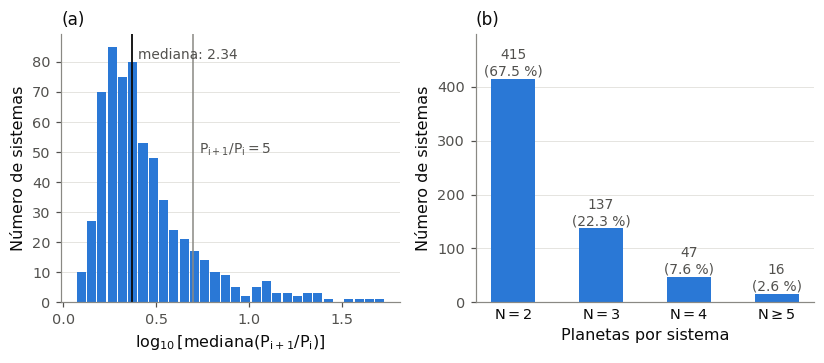

In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.4))
ax = ejes[0]
ax.hist(sistemas["log_median_period_ratio"], bins=30, color=COLOR_UNICO, rwidth=0.88)
mediana = sistemas["log_median_period_ratio"].median()
ax.axvline(mediana, color=TINTA, linewidth=1.2)
ax.text(mediana + 0.03, ax.get_ylim()[1] * 0.95, f"mediana: {sistemas['median_period_ratio'].median():.2f}",
        fontsize=9, color=TINTA_SECUNDARIA, va="top")
ax.axvline(np.log10(UMBRAL_GAPPED), color=GRIS, linewidth=1.0)
ax.text(np.log10(UMBRAL_GAPPED) + 0.03, ax.get_ylim()[1] * 0.6, r"$P_{i+1}/P_i = 5$",
        fontsize=9, color=TINTA_SECUNDARIA, va="top")
ax.set_xlabel(EJE["espaciamiento"])
ax.set_ylabel("Número de sistemas")
ax.grid(axis="x", visible=False)
etiqueta_panel(ax, "a")

ax = ejes[1]
conteo = sistemas["multiplicidad"].value_counts().reindex(["N = 2", "N = 3", "N = 4", "N >= 5"])
x = np.arange(len(conteo))
ax.bar(x, conteo.values, width=0.5, color=COLOR_UNICO)
for xi, v in zip(x, conteo.values):
    ax.text(xi, v + 6, f"{v}\n({100 * v / n:.1f} %)", ha="center", fontsize=9, color=TINTA_SECUNDARIA)
ax.set_xticks(x)
ax.set_xticklabels([r"$N = 2$", r"$N = 3$", r"$N = 4$", r"$N \geq 5$"])
ax.tick_params(axis="x", length=0, labelcolor=TINTA)
ax.set_ylim(0, conteo.max() * 1.2)
ax.set_xlabel("Planetas por sistema")
ax.set_ylabel("Número de sistemas")
ax.grid(axis="x", visible=False)
etiqueta_panel(ax, "b")
fig.tight_layout()
guardar_figura(fig, "A3-F1", "panorama_de_la_arquitectura",
               titulo=("Muestra de sistemas multiplanetarios. (a) Distribución del espaciamiento orbital; la línea negra marca la "
                       "mediana y la gris, la razón de períodos de 5 que define un sistema gapped. (b) Multiplicidad observada."),
               seccion="6.4", nota=f"N = {n} sistemas; {sistemas['gapped'].sum()} gapped ({100 * sistemas['gapped'].mean():.1f} %).")
plt.show()

## 2. Exploración bivariada (preliminar)

Asociación directa de cada propiedad estelar con las dos respuestas, sin controles: correlación de Spearman con el espaciamiento (IC 95 % por *bootstrap*) y prueba de Mann–Whitney entre sistemas *gapped* y no *gapped*.

In [6]:
filas = []
for variable in ["st_mass", "st_met"]:
    s = spearman(sistemas[variable], sistemas["median_period_ratio"])
    filas.append({"predictor": variable, "respuesta": "median_period_ratio", "prueba": "Spearman", "N": s["N"],
                  "estadistico": s["rho"], "IC95_inf": s["rho_IC95_inf"], "IC95_sup": s["rho_IC95_sup"],
                  "diferencia_medianas": np.nan, "valor_p": s["valor_p"]})
    mw = mann_whitney(sistemas.loc[sistemas["gapped"] == 0, variable], sistemas.loc[sistemas["gapped"] == 1, variable])
    filas.append({"predictor": variable, "respuesta": "gapped", "prueba": "Mann-Whitney", "N": mw["N_0"] + mw["N_1"],
                  "estadistico": mw["biserial_rangos"], "IC95_inf": np.nan, "IC95_sup": np.nan,
                  "diferencia_medianas": mw["diferencia_medianas"], "valor_p": mw["valor_p"]})
tabla_bivariada = guardar_tabla(
    pd.DataFrame(filas), "A3-T4", "exploracion_bivariada",
    titulo="Análisis III: asociación bivariada de la masa estelar y la metalicidad con el espaciamiento orbital y con la condición gapped.",
    seccion="6.4", destino="anexo",
    nota=("Estadístico: rho de Spearman (IC 95 % por bootstrap, 5000 remuestreos) o correlación biserial por rangos, "
          "positiva si los sistemas gapped tienen valores mayores. Diferencia de medianas: gapped menos no gapped."),
    encabezados={"respuesta": "Respuesta", "prueba": "Prueba", "estadistico": "Estadístico", "diferencia_medianas": "Dif. medianas"})
tabla_bivariada

Tabla A3-T4 guardada: tablas/A3-T4_exploracion_bivariada.csv


,predictor,respuesta,prueba,N,estadistico,IC95_inf,IC95_sup,diferencia_medianas,valor_p
0,st_mass,median_period_ratio,Spearman,615,-0.1104,-0.1867,-0.0297,NaN,0.00615
1,st_mass,gapped,Mann-Whitney,615,-0.1637,NaN,NaN,-0.036,0.01530
2,st_met,median_period_ratio,Spearman,615,0.0237,-0.0544,0.1008,NaN,0.55800
3,st_met,gapped,Mann-Whitney,615,0.0651,NaN,NaN,0.016,0.33500


## 3. Espaciamiento orbital (sección 6.4.1)

In [7]:
y_esp = sistemas["log_median_period_ratio"]
S0 = ajustar_lineal(y_esp, matriz(sistemas, CONTROLES), nombre="S0")
S1 = ajustar_lineal(y_esp, matriz(sistemas, CONTROLES + ESTELARES), nombre="S1")
formulas = {"S0": " + ".join(CONTROLES), "S1": " + ".join(CONTROLES + ESTELARES),
            "G0": " + ".join(CONTROLES), "G1": " + ".join(CONTROLES + ESTELARES)}

comparacion_S = comparar_modelos({"S0": S0, "S1": S1}, formulas, deltas=["R2", "AIC", "BIC", "RMSE"])
tabla_S = guardar_tabla(
    comparacion_S.rename(columns={"N": "N_sistemas"}), "A3-T5", "comparacion_modelos_espaciamiento",
    titulo="Análisis III: comparación de los modelos lineales del espaciamiento orbital. Diferencias respecto al modelo base S0.",
    seccion="6.4.1", nota="Respuesta: logaritmo decimal de la mediana de las razones de período adyacentes. RMSE y MAE en dex.",
    formatos={"delta_AIC": "{:+.1f}", "delta_BIC": "{:+.1f}", "delta_R2": "{:+.4f}", "delta_RMSE": "{:+.4f}",
              "AIC": "{:.1f}", "BIC": "{:.1f}"})
display(tabla_S)
print(pd.Series(razon_verosimilitud(S0, S1)).to_string())

Tabla A3-T5 guardada: tablas/A3-T5_comparacion_modelos_espaciamiento.csv


,modelo,predictores,N_sistemas,R2,R2_ajustado,AIC,BIC,RMSE,MAE,delta_R2,delta_AIC,delta_BIC,delta_RMSE
0,S0,median_radius_z + N_planetas_z,615,0.0698,0.0668,50.464,63.7288,0.2509,0.1796,0.0000,0.000,0.0000,0.0000
1,S1,median_radius_z + N_planetas_z + st_mass_z + s...,615,0.0927,0.0868,39.141,61.2491,0.2478,0.1763,0.0229,-11.323,-2.4798,-0.0031


comparacion     S0 vs S1
LR             15.323016
gl                     2
valor_p         0.000471


In [8]:
tabla_coef_S = guardar_tabla(
    S1.coeficientes(), "A3-T6", "coeficientes_espaciamiento",
    titulo="Análisis III: coeficientes estandarizados del modelo estelar S1 del espaciamiento orbital.",
    seccion="6.4.1", nota="Cambio en el logaritmo del espaciamiento (dex) por una desviación estándar del predictor.")
tabla_coef_S

Tabla A3-T6 guardada: tablas/A3-T6_coeficientes_espaciamiento.csv


,modelo,predictor,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p
0,S1,const,0.4418,0.0100,0.4221,0.4615,1.320000e-191
1,S1,median_radius_z,0.0269,0.0105,0.0062,0.0476,1.090000e-02
2,S1,N_planetas_z,-0.0670,0.0100,-0.0868,-0.0473,5.620000e-11
3,S1,st_mass_z,-0.0426,0.0109,-0.0640,-0.0212,1.040000e-04
4,S1,st_met_z,0.0147,0.0106,-0.0061,0.0355,1.660000e-01


## 4. Sistemas *gapped* (sección 6.4.2)

In [9]:
y_gap = sistemas["gapped"]
G0 = ajustar_logit(y_gap, matriz(sistemas, CONTROLES), nombre="G0")
G1 = ajustar_logit(y_gap, matriz(sistemas, CONTROLES + ESTELARES), nombre="G1")

comparacion_G = comparar_modelos({"G0": G0, "G1": G1}, formulas, deltas=["pseudo_R2", "AIC", "BIC", "log_loss", "brier"])
lr_G = razon_verosimilitud(G0, G1)
tabla_G = guardar_tabla(
    comparacion_G.rename(columns={"N": "N_sistemas"}), "A3-T7", "comparacion_modelos_gapped",
    titulo="Análisis III: comparación de los modelos logísticos de la condición gapped. Diferencias respecto al modelo base G0.",
    seccion="6.4.2",
    nota=(f"{int(y_gap.sum())} de {len(y_gap)} sistemas son gapped. Prueba de razón de verosimilitud G0 frente a G1: "
          f"LR = {lr_G['LR']:.2f}, {lr_G['gl']} g.l., p = {lr_G['valor_p']:.4f}."),
    formatos={"delta_AIC": "{:+.1f}", "delta_BIC": "{:+.1f}", "delta_pseudo_R2": "{:+.4f}", "delta_log_loss": "{:+.4f}",
              "delta_brier": "{:+.4f}", "AIC": "{:.1f}", "BIC": "{:.1f}", "pseudo_R2": "{:.4f}", "log_loss": "{:.4f}", "brier": "{:.4f}"})
tabla_G

Tabla A3-T7 guardada: tablas/A3-T7_comparacion_modelos_gapped.csv


,modelo,predictores,N_sistemas,pseudo_R2,AIC,BIC,log_loss,brier,delta_pseudo_R2,delta_AIC,delta_BIC,delta_log_loss,delta_brier
0,G0,median_radius_z + N_planetas_z,615,0.0184,491.0180,504.2828,0.3943,0.1176,0.0000,0.0000,0.0000,0.0000,0.0000
1,G1,median_radius_z + N_planetas_z + st_mass_z + s...,615,0.0392,484.7364,506.8445,0.3860,0.1159,0.0208,-6.2816,2.5617,-0.0084,-0.0018


In [10]:
tabla_coef_G = guardar_tabla(
    G1.coeficientes(), "A3-T8", "razones_de_momios_gapped",
    titulo="Análisis III: coeficientes y razones de momios del modelo estelar G1 de la condición gapped.",
    seccion="6.4.2", nota="OR por una desviación estándar del predictor.")
tabla_coef_G

Tabla A3-T8 guardada: tablas/A3-T8_razones_de_momios_gapped.csv


,modelo,predictor,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p,OR,OR_IC95_inf,OR_IC95_sup
0,G1,const,-1.9361,0.1287,-2.1883,-1.6839,3.530000e-51,0.1443,0.1121,0.1856
1,G1,median_radius_z,0.0514,0.1266,-0.1967,0.2995,6.850000e-01,1.0528,0.8215,1.3492
2,G1,N_planetas_z,-0.4284,0.1614,-0.7449,-0.1120,7.960000e-03,0.6515,0.4748,0.8940
3,G1,st_mass_z,-0.3529,0.1227,-0.5933,-0.1125,4.010000e-03,0.7027,0.5525,0.8936
4,G1,st_met_z,0.2651,0.1267,0.0168,0.5133,3.640000e-02,1.3035,1.0169,1.6708


## 5. Efectos estelares sobre la arquitectura

Figura A3-F2 guardada: figuras/A3-F2_efectos_estelares_sobre_la_arquitectura.png y .pdf


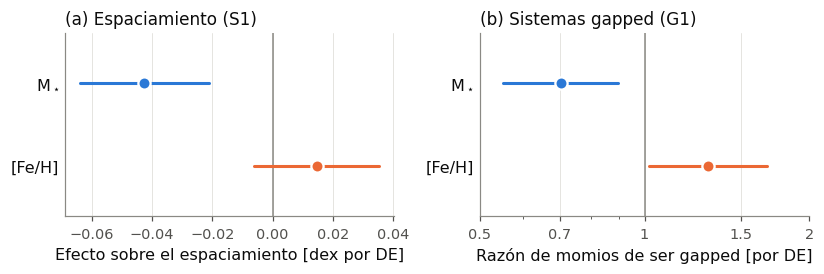

In [11]:
cS = S1.coeficientes(solo=ESTELARES).set_index("predictor").loc[ESTELARES]
cG = G1.coeficientes(solo=ESTELARES).set_index("predictor").loc[ESTELARES]
colores = [COLOR_MASA_ESTELAR, COLOR_METALICIDAD]
fig, ejes = plt.subplots(1, 2, figsize=(7.6, 2.6))
grafico_efectos(ejes[0], [r"$M_\star$", "[Fe/H]"], cS["coeficiente"], cS["IC95_inf"], cS["IC95_sup"], colores)
ejes[0].set_xlabel("Efecto sobre el espaciamiento [dex por DE]")
etiqueta_panel(ejes[0], "a", "Espaciamiento (S1)")
grafico_efectos(ejes[1], [r"$M_\star$", "[Fe/H]"], cG["OR"], cG["OR_IC95_inf"], cG["OR_IC95_sup"], colores, referencia=1.0)
ejes[1].set_xscale("log")
ejes[1].set_xticks([0.5, 0.7, 1.0, 1.5, 2.0])
ejes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ejes[1].xaxis.set_minor_formatter(plt.NullFormatter())
ejes[1].set_xlabel("Razón de momios de ser gapped [por DE]")
etiqueta_panel(ejes[1], "b", "Sistemas gapped (G1)")
fig.tight_layout()
guardar_figura(fig, "A3-F2", "efectos_estelares_sobre_la_arquitectura",
               titulo=("Efecto de la masa estelar y de la metalicidad sobre la arquitectura, por una desviación estándar del predictor: "
                       "(a) coeficientes del modelo de espaciamiento S1; (b) razones de momios del modelo G1 (escala logarítmica). "
                       "Las barras son intervalos de confianza al 95 %."),
               seccion="6.4.2")
plt.show()

## 6. Verificación de robustez

Los radios de los planetas que no transitan son estimaciones del archivo. Se repiten S1 y G1 en los sistemas cuyos planetas se observaron todos en tránsito, y en los sistemas de Kepler.

In [12]:
def efectos_estelares(nombre, muestra):
    m = estandarizar(muestra, ["median_radius", "N_planetas", "st_mass", "st_met"])
    s1 = ajustar_lineal(m["log_median_period_ratio"], matriz(m, CONTROLES + ESTELARES), nombre="S1")
    g1 = ajustar_logit(m["gapped"], matriz(m, CONTROLES + ESTELARES), nombre="G1")
    filas = []
    for modelo, tabla, efecto in [("S1", s1.coeficientes(solo=ESTELARES), "coeficiente"), ("G1", g1.coeficientes(solo=ESTELARES), "OR")]:
        for f in tabla.itertuples():
            inf, sup = (f.IC95_inf, f.IC95_sup) if modelo == "S1" else (f.OR_IC95_inf, f.OR_IC95_sup)
            filas.append({"muestra": nombre, "N_sistemas": len(m), "N_gapped": int(m["gapped"].sum()), "modelo": modelo,
                          "predictor": f.predictor, "medida": efecto, "efecto": getattr(f, efecto),
                          "IC95_inf": inf, "IC95_sup": sup, "valor_p": f.valor_p})
    return filas

robustez = pd.DataFrame(
    efectos_estelares("Todos los sistemas (principal)", sistemas)
    + efectos_estelares("Todos los planetas en tránsito", sistemas[sistemas["todos_en_transito"]])
    + efectos_estelares("Sistemas de Kepler", sistemas[sistemas["origen_observacional"] == "Kepler"]))
tabla_robustez = guardar_tabla(
    robustez, "A3-T9", "robustez_efectos_estelares",
    titulo="Análisis III: efectos de la masa estelar y la metalicidad en submuestras de robustez.",
    seccion="6.4", destino="anexo",
    nota="Coeficiente estandarizado en S1 (espaciamiento) y razón de momios por desviación estándar en G1 (gapped).",
    encabezados={"N_gapped": "Gapped", "medida": "Medida", "efecto": "Efecto"})
tabla_robustez

Tabla A3-T9 guardada: tablas/A3-T9_robustez_efectos_estelares.csv


,muestra,N_sistemas,N_gapped,modelo,predictor,medida,efecto,IC95_inf,IC95_sup,valor_p
0,Todos los sistemas (principal),615,85,S1,st_mass_z,coeficiente,-0.0426,-0.0640,-0.0212,0.000104
1,Todos los sistemas (principal),615,85,S1,st_met_z,coeficiente,0.0147,-0.0061,0.0355,0.166000
2,Todos los sistemas (principal),615,85,G1,st_mass_z,OR,0.7027,0.5525,0.8936,0.004010
3,Todos los sistemas (principal),615,85,G1,st_met_z,OR,1.3035,1.0169,1.6708,0.036400
4,Todos los planetas en tránsito,542,68,S1,st_mass_z,coeficiente,-0.0273,-0.0501,-0.0045,0.019200
5,Todos los planetas en tránsito,542,68,S1,st_met_z,coeficiente,0.0136,-0.0087,0.0359,0.231000
6,Todos los planetas en tránsito,542,68,G1,st_mass_z,OR,0.8068,0.6162,1.0564,0.118000
7,Todos los planetas en tránsito,542,68,G1,st_met_z,OR,1.2384,0.9437,1.6251,0.123000
8,Sistemas de Kepler,389,45,S1,st_mass_z,coeficiente,-0.0248,-0.0489,-0.0007,0.044000
9,Sistemas de Kepler,389,45,S1,st_met_z,coeficiente,0.0172,-0.0065,0.0410,0.154000


## Lectura de los resultados

- Añadir la estrella mejora poco, pero de forma detectable, los dos modelos de arquitectura (tablas A3-T5 y A3-T7).
- La masa estelar es el predictor más consistente: a mayor masa estelar, menor espaciamiento y menores momios de ser *gapped* (tablas A3-T6 y A3-T8, figura A3-F2).
- La metalicidad no se asocia con el espaciamiento y muestra una asociación débil con la condición *gapped*.
- **Cautela (tabla A3-T9):** al restringir a sistemas con todos sus planetas observados en tránsito, el efecto de la masa estelar sobre el espaciamiento se mantiene pero se debilita, y los efectos sobre la condición *gapped* dejan de distinguirse de cero. El resultado sobre *gapped* depende de los sistemas con planetas de velocidad radial, cuyos radios son estimados.
- Dos tercios de los sistemas tienen solo dos planetas; la arquitectura observada puede estar incompleta.